# 01 — Data understanding and preprocessing

Rubric item: *Data understanding and preprocessing*. This notebook looks at the dataset before any model is trained and checks the data conversion we rely on later.

Numbers come from `results/eda.json` (written by `scripts/01_eda.py`) and the competition annotation files in `data/`. Figures are drawn by `scripts/08_figures.py`. The last section is left empty on purpose: the observations and the choices they lead to are yours to write.

In [1]:
import json, sys, tempfile
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import CLASS_NAMES, data_root, index_annotations, load_coco, sample_frames
from data import export_yolo

DATA = data_root()
S = json.loads((ROOT / "results" / "eda.json").read_text())["summary"]
show = lambda name, width=900: display(Image(filename=str(ROOT / "images" / name), width=width))

## 1. What is in the dataset

In [2]:
header = ["split", "clips", "frames", "labelled objects", "ignored regions", "frames per clip"]
rows = [[s, S[s]["clips"], f'{S[s]["frames"]:,}', f'{S[s]["objects"]:,}', f'{S[s]["ignored_regions"]:,}', round(S[s]["frames"] / S[s]["clips"])] for s in ("train", "val")]
rows.append(["test", S["test"]["clips"], f'{S["test"]["frames"]:,}', "no labels", "-", round(S["test"]["frames"] / S["test"]["clips"])])
table = [header, ["---"] * len(header)] + rows
display(Markdown("\n".join("| " + " | ".join(map(str, r)) + " |" for r in table)))

| split | clips | frames | labelled objects | ignored regions | frames per clip |
| --- | --- | --- | --- | --- | --- |
| train | 56 | 24,201 | 1,105,516 | 510,744 | 432 |
| val | 7 | 2,846 | 114,132 | 31,960 | 407 |
| test | 48 | 3,811 | no labels | - | 79 |

## 2. Class balance

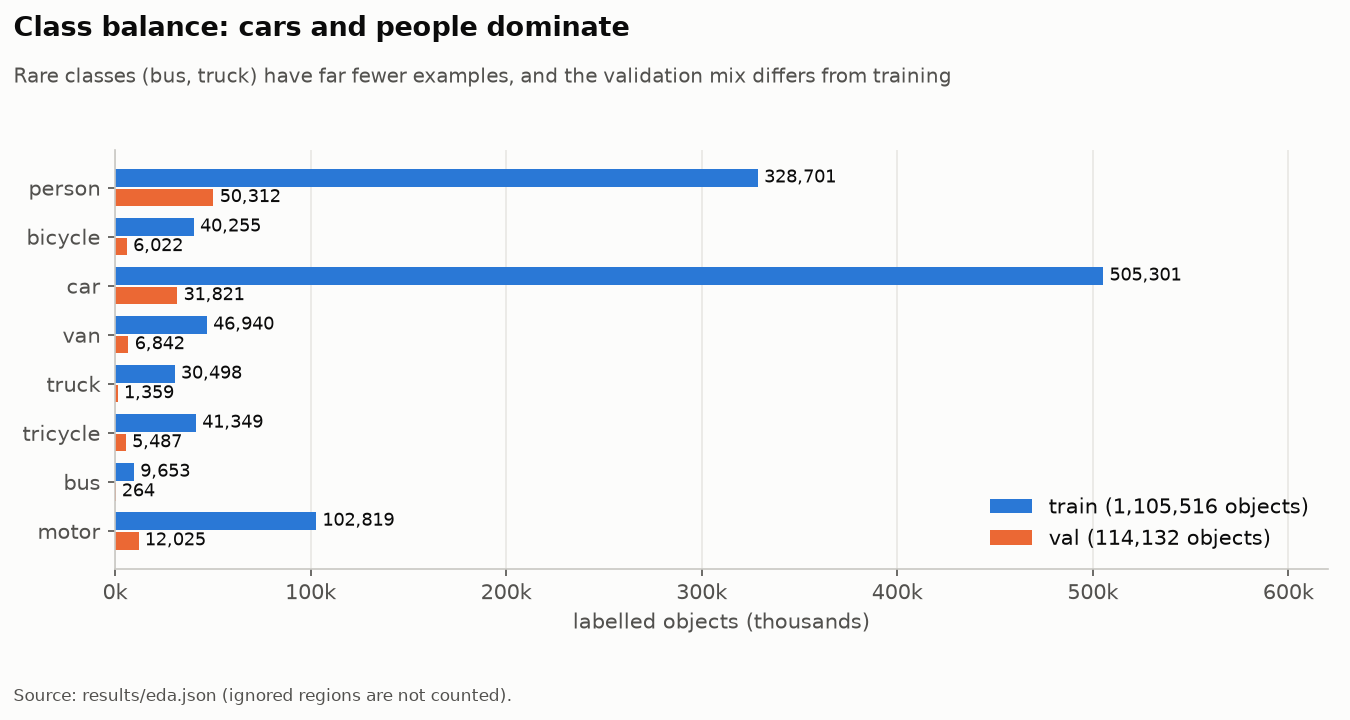

share of training objects: {'person': '29.7%', 'bicycle': '3.6%', 'car': '45.7%', 'van': '4.2%', 'truck': '2.8%', 'tricycle': '3.7%', 'bus': '0.9%', 'motor': '9.3%'}


In [3]:
show("fig_data_classes.png")
train_counts = S["train"]["class_counts"]
total = sum(train_counts.values())
print("share of training objects:", {name: f"{n / total:.1%}" for name, n in train_counts.items()})

## 3. Object size

Sizes are in original pixels. COCO calls an object *small* below 32x32 px and *large* above 96x96 px, and AP small is one of the reported metrics.

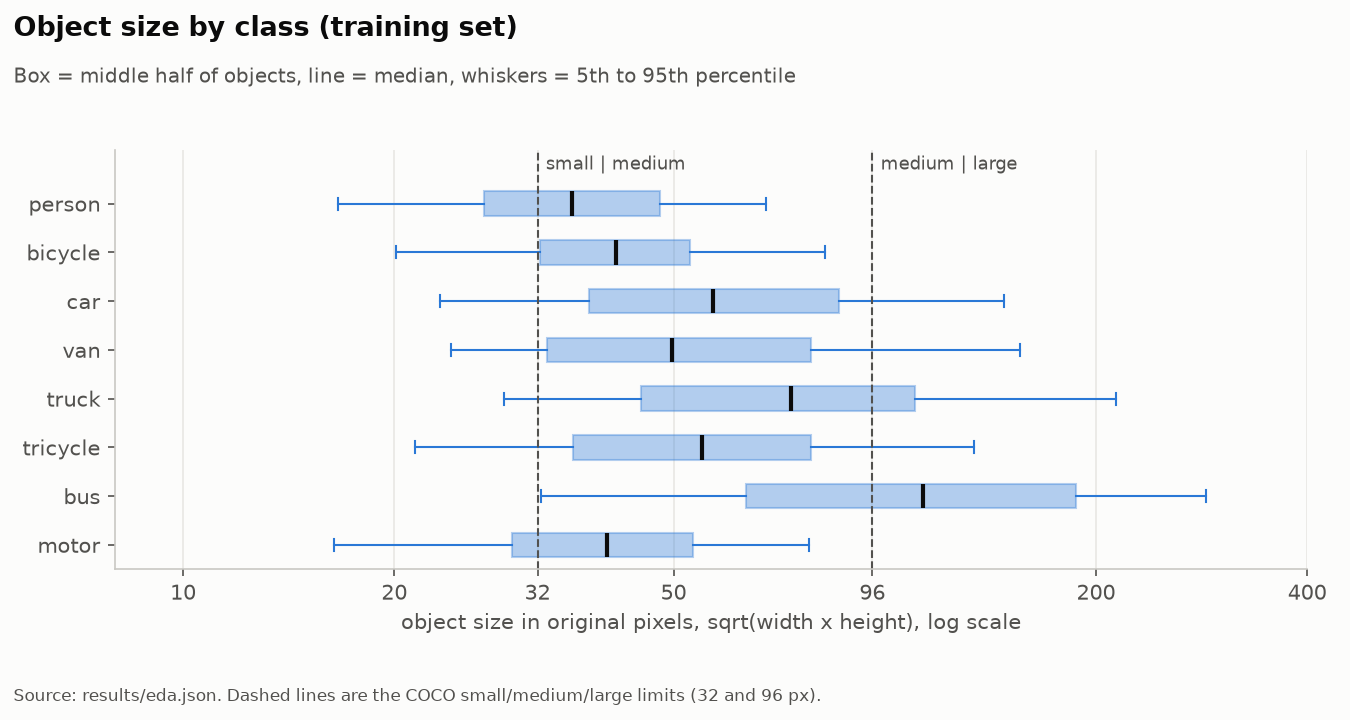

train size buckets: {'large': 0.116, 'medium': 0.635, 'small': 0.249} | sqrt(area) percentiles: {'p5': 19.7, 'p25': 32.0, 'p50': 45.8, 'p75': 67.9, 'p95': 130.2}
val size buckets: {'large': 0.113, 'medium': 0.695, 'small': 0.192} | sqrt(area) percentiles: {'p5': 22.6, 'p25': 35.5, 'p50': 52.4, 'p75': 73.2, 'p95': 130.7}


In [4]:
show("fig_data_sizes.png")
for split in ("train", "val"):
    print(split, "size buckets:", S[split]["size_bucket_share"], "| sqrt(area) percentiles:", S[split]["sqrt_area_px"])

## 4. Scene density across clips

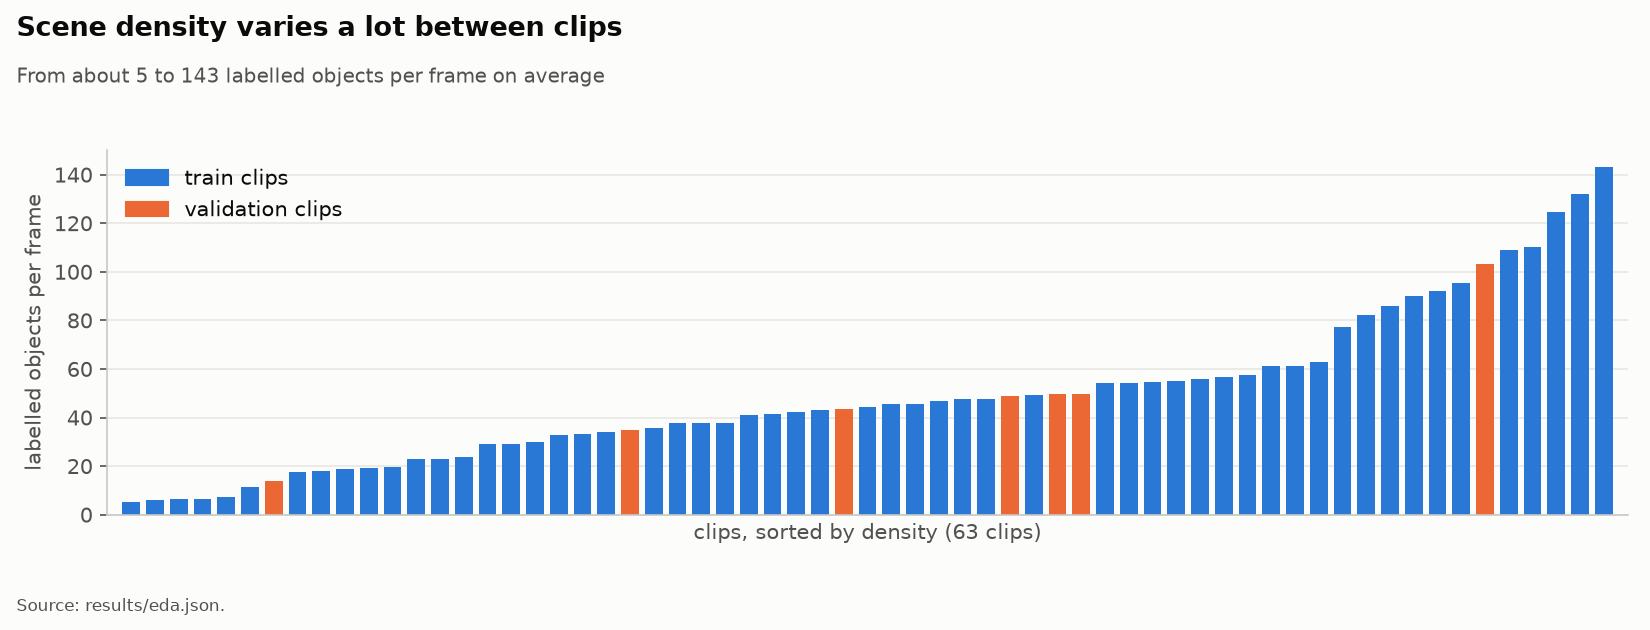

objects per frame across 63 clips: min 5.1, median 44.2, max 143.0
within a frame (train), percentiles: {'p5': 6.0, 'p25': 22.0, 'p50': 43.0, 'p75': 57.0, 'p95': 118.0, 'mean': 45.7, 'max': 180}


In [5]:
show("fig_data_density.png", 1000)
density = sorted(c["objects_per_frame"] for s in ("train", "val") for c in S[s]["per_clip"].values())
print(f"objects per frame across {len(density)} clips: min {density[0]}, median {density[len(density) // 2]}, max {density[-1]}")
print("within a frame (train), percentiles:", S["train"]["objects_per_frame"])

## 5. Ignored regions and non-target classes

Annotations with `iscrowd = 1` mark crowds, areas too packed to label, and VisDrone's "others" category. Scoring does not penalise detections inside them. In our conversion they are kept out of the object labels; training can also paint them grey (`--mask-ignored`) so unlabelled crowds are not learned as background.

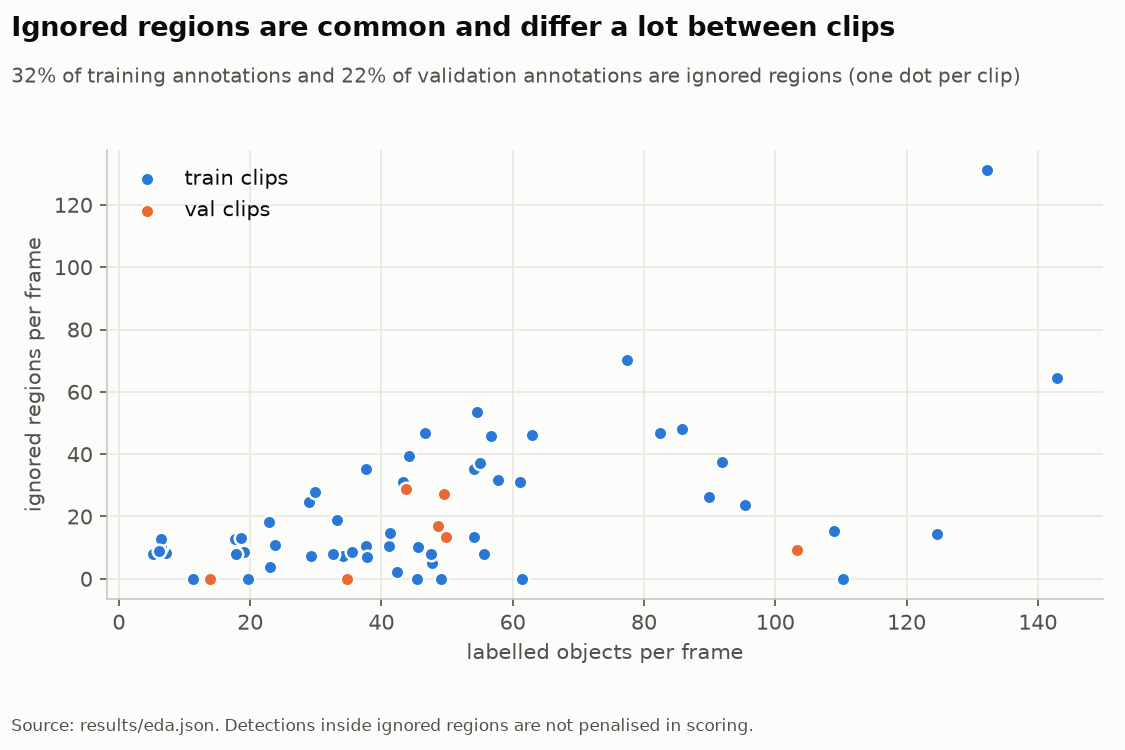

train: 510,744 ignored regions = 32% of all annotations
val: 31,960 ignored regions = 22% of all annotations


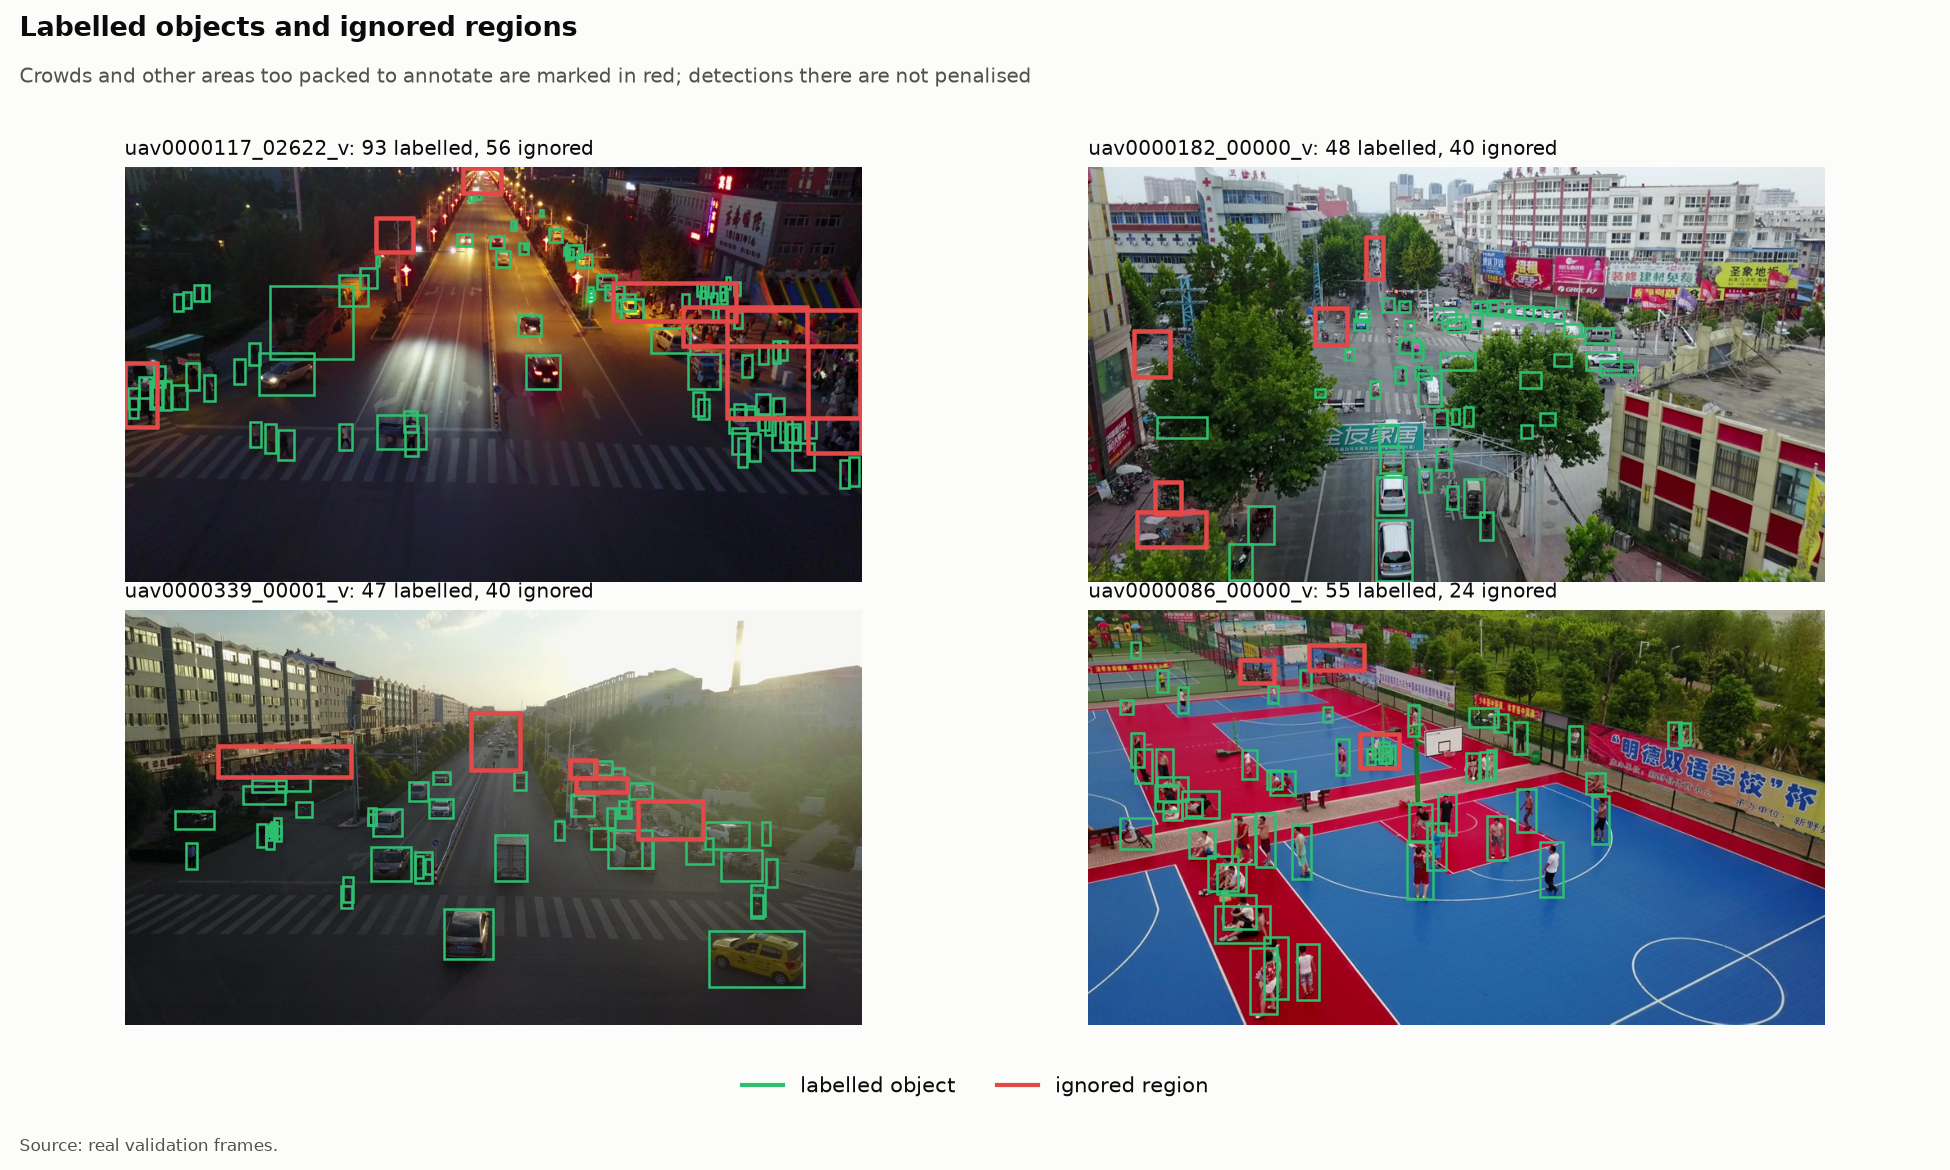

In [6]:
show("fig_data_ignored.png", 700)
for split in ("train", "val"):
    n_obj, n_ign = S[split]["objects"], S[split]["ignored_regions"]
    print(f"{split}: {n_ign:,} ignored regions = {n_ign / (n_obj + n_ign):.0%} of all annotations")
show("fig_qual_ignored_regions.png", 1000)   # green = labelled objects, red = ignored regions

## 6. Train / validation split is by sequence

Frames of one clip are almost identical, so the split is made by clip. The check below fails if any clip appears in both.

56 training clips, 7 validation clips, shared clips: 0


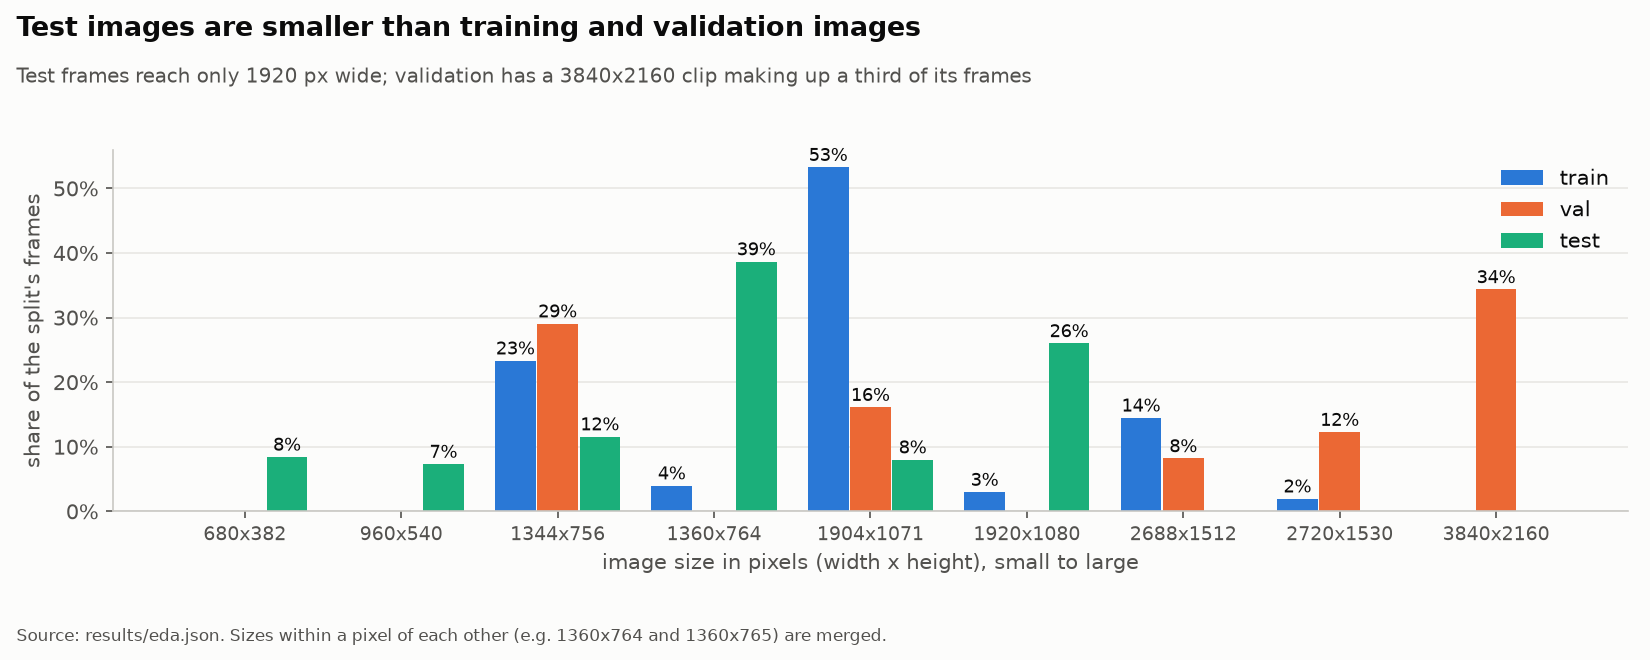

In [7]:
train_clips, val_clips = set(S["train"]["per_clip"]), set(S["val"]["per_clip"])
assert not train_clips & val_clips, "a clip is in both splits"
print(f"{len(train_clips)} training clips, {len(val_clips)} validation clips, shared clips: {len(train_clips & val_clips)}")
show("fig_data_resolution.png", 1000)

## 7. Frame sampling

Neighbouring frames barely differ, so training uses every Nth frame of each clip. The figure shows how much changes between frames k apart.

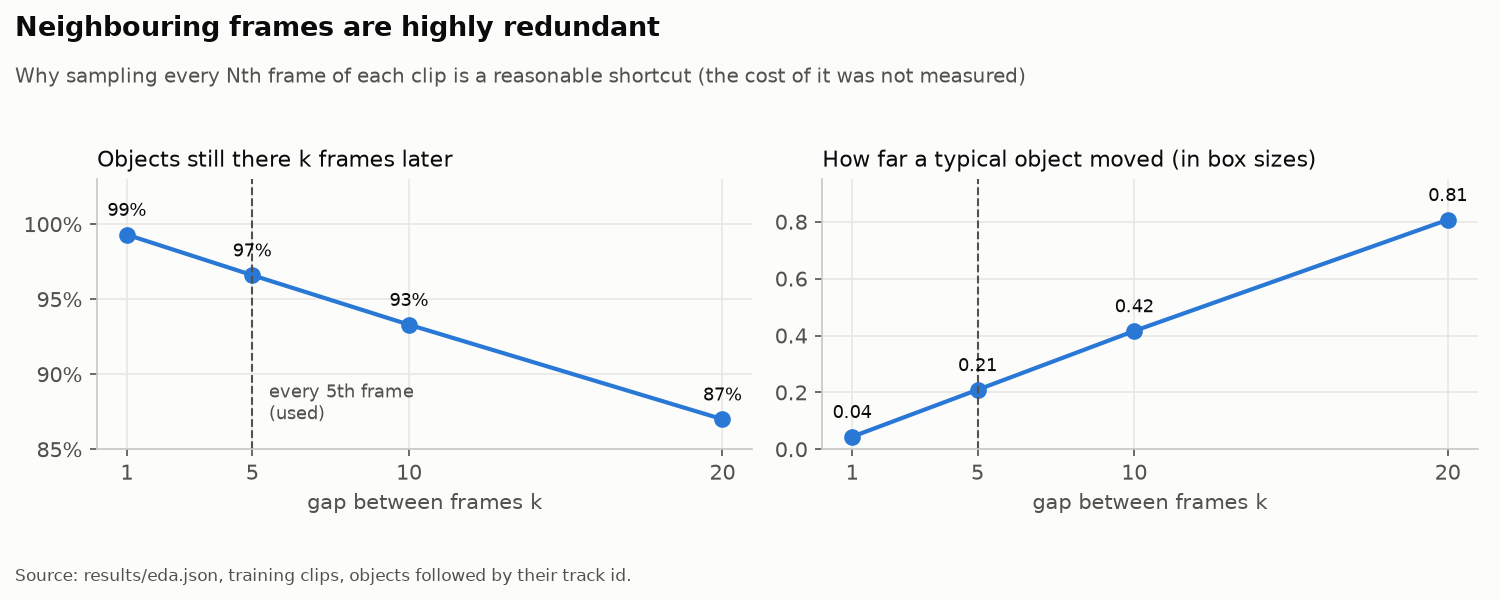

every  1th frame: 24,201 training frames


every  2th frame: 12,114 training frames
every  5th frame:  4,868 training frames
every 10th frame:  2,446 training frames
stride 5 reproduces the 4,868-frame sample from all 56 clips


In [8]:
show("fig_data_stride.png", 900)
train = load_coco(DATA, "train")
for stride in (1, 2, 5, 10):
    print(f"every {stride:>2}th frame: {len(sample_frames(train['images'], stride)):>6,} training frames")
sample = sample_frames(train["images"], 5)
assert len(sample) == 4868 and len({i["video"] for i in sample}) == 56   # the sample used in the Colab runs
print("stride 5 reproduces the 4,868-frame sample from all 56 clips")

## 8. Format conversion, checked

COCO ids are 1-based and boxes are `[x, y, w, h]` in pixels. YOLO labels and the submission use 0-based ids; YOLO boxes are normalised centre/size. The cell converts the sampled frames and checks the counts and class range.

In [9]:
print("COCO id -> name -> YOLO / submission id:", {i + 1: (n, i) for i, n in enumerate(CLASS_NAMES)})
objects, _ = index_annotations(train)
expected = sum(len(objects[i["id"]]) for i in sample)
with tempfile.TemporaryDirectory() as tmp:
    export_yolo(DATA, Path(tmp) / "yolo", stride=5, val_stride=1)
    lines = [l.split() for p in (Path(tmp) / "yolo" / "labels" / "train").rglob("*.txt") for l in p.read_text().splitlines() if l]
classes = {int(l[0]) for l in lines}
values = [float(v) for l in lines for v in l[1:]]
print(f"labelled objects in sampled frames: {expected:,} | YOLO label lines written: {len(lines):,}")
print("class ids used:", sorted(classes), "| all box values within 0-1:", all(0 <= v <= 1 for v in values))
assert classes <= set(range(8)) and all(0 <= v <= 1 for v in values) and len(lines) >= 0.999 * expected

COCO id -> name -> YOLO / submission id: {1: ('person', 0), 2: ('bicycle', 1), 3: ('car', 2), 4: ('van', 3), 5: ('truck', 4), 6: ('tricycle', 5), 7: ('bus', 6), 8: ('motor', 7)}


labelled objects in sampled frames: 222,879 | YOLO label lines written: 222,879
class ids used: [0, 1, 2, 3, 4, 5, 6, 7] | all box values within 0-1: True


## 9. Preprocessing the models use

| Models | Resize | Normalisation | Augmentation |
|---|---|---|---|
| Faster R-CNN, RetinaNet (TorchVision) | short side 800 px, long side at most 1333 px (`--min-size`, `--max-size`) | pixels scaled to 0-1, then ImageNet mean/std inside the model | optional horizontal flip (`--flip`) |
| YOLO26, RT-DETR (Ultralytics) | letterbox to `--imgsz` (640 so far) | pixels scaled to 0-1 | Ultralytics defaults; the exact values are saved in `results/runs/<run>/config.json` |

All runs use seed 42, a fixed per-clip frame sample, and validation on whole validation clips.